In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv(r"C:\Users\geeth\OneDrive\Desktop\Data Analysis Projects\IPL Project\innings_deliveries.csv")
print(df.head(10))
print(df.info())
print(df.shape)
print(df.columns)
print(df.dtypes)

                          team  over        batter    bowler   non_striker  \
0  Royal Challengers Bengaluru     0       V Kohli  I Sharma  F du Plessis   
1  Royal Challengers Bengaluru     0       V Kohli  I Sharma  F du Plessis   
2  Royal Challengers Bengaluru     0  F du Plessis  I Sharma       V Kohli   
3  Royal Challengers Bengaluru     0       V Kohli  I Sharma  F du Plessis   
4  Royal Challengers Bengaluru     0       V Kohli  I Sharma  F du Plessis   
5  Royal Challengers Bengaluru     0       V Kohli  I Sharma  F du Plessis   
6  Royal Challengers Bengaluru     1  F du Plessis  KK Ahmed       V Kohli   
7  Royal Challengers Bengaluru     1  F du Plessis  KK Ahmed       V Kohli   
8  Royal Challengers Bengaluru     1  F du Plessis  KK Ahmed       V Kohli   
9  Royal Challengers Bengaluru     1       V Kohli  KK Ahmed  F du Plessis   

   runs_batter  runs_extras  runs_total player_out wicket_kind fielders  
0            0            0           0        NaN         NaN     

In [2]:
print(df.isnull().sum())

team             0
over             0
batter           0
bowler           0
non_striker      0
runs_batter      0
runs_extras      0
runs_total       0
player_out     228
wicket_kind    228
fielders         0
dtype: int64


In [3]:
print(df.duplicated().sum())

56


In [4]:
runs_per_over=df.groupby(["team","over"])["runs_total"].sum()
print(runs_per_over)

team                         over
Delhi Capitals               0        9
                             1       15
                             2        4
                             3        2
                             4       13
                             5       11
                             6        9
                             7        8
                             8       10
                             9        6
                             10       3
                             11      10
                             12      16
                             13       8
                             14       3
                             15       3
                             16       3
                             17       2
                             18       5
                             19       0
Royal Challengers Bengaluru  0       10
                             1       13
                             2        2
                             3       12
      

In [5]:
rcb_runs=df[df["team"]=="Royal Challengers Bengaluru"].groupby("over")["runs_total"].sum()
dc_runs=df[df["team"]=="Delhi Capitals"].groupby("over")["runs_total"].sum()
print("********RCB Runs********")
print(rcb_runs)
print("********DC Runs********")
print(dc_runs)

********RCB Runs********
over
0     10
1     13
2      2
3     12
4     14
5     10
6     15
7     11
8     12
9     11
10     8
11     3
12    10
13     3
14     4
15     9
16    22
17     5
18     5
19     8
Name: runs_total, dtype: int64
********DC Runs********
over
0      9
1     15
2      4
3      2
4     13
5     11
6      9
7      8
8     10
9      6
10     3
11    10
12    16
13     8
14     3
15     3
16     3
17     2
18     5
19     0
Name: runs_total, dtype: int64


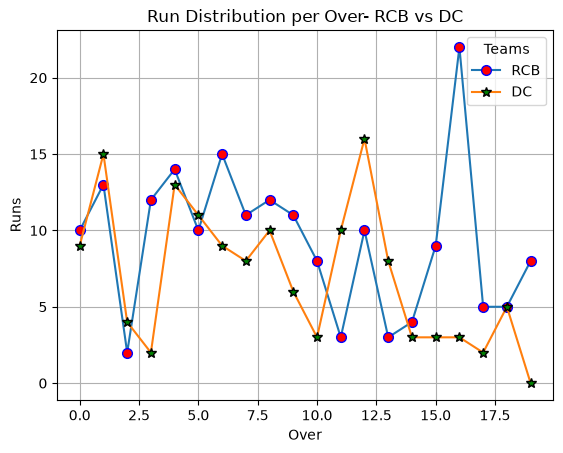

In [6]:
plt.plot(rcb_runs.index,rcb_runs.values,marker='o',ms=7,mfc='red',label="RCB",mec='blue')
plt.plot(dc_runs.index,dc_runs.values,marker='*',ms=7,mfc='green',label="DC",mec='black')
plt.title("Run Distribution per Over- RCB vs DC")
plt.xlabel("Over")
plt.ylabel("Runs")
plt.legend(title="Teams",loc="upper right")
plt.grid(True)
plt.show()

In [7]:
batter_runs=df.groupby("batter")["runs_batter"].sum()
batter_runs=batter_runs.sort_values(ascending=False)
print(batter_runs.head(10))

batter
AR Patel           57
RM Patidar         52
WG Jacks           41
C Green            32
SD Hope            29
V Kohli            27
J Fraser-McGurk    21
MK Lomror          13
Rasikh Salam       10
Kuldeep Yadav       6
Name: runs_batter, dtype: int64


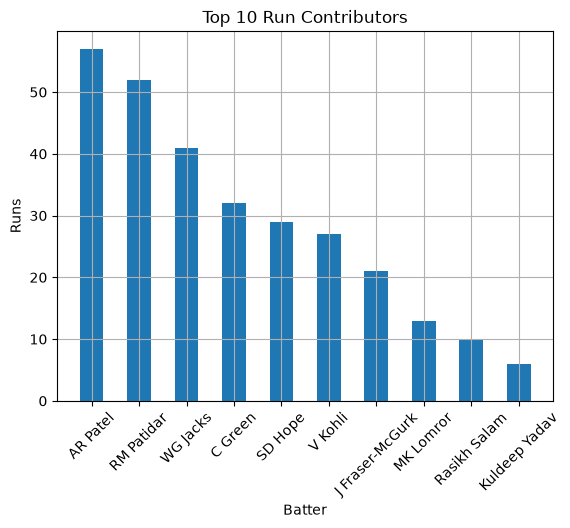

In [8]:
top_batters=batter_runs.head(10)
plt.bar(top_batters.index,top_batters.values,width=0.5)
plt.title("Top 10 Run Contributors")
plt.xlabel("Batter")
plt.ylabel("Runs")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [9]:
wickets=df[df["player_out"].notnull()].groupby("bowler")["player_out"].count()
print(wickets.sort_values(ascending=False))

bowler
Yash Dayal        4
Mukesh Kumar      3
Rasikh Salam      2
C Green           2
KK Ahmed          2
LH Ferguson       2
I Sharma          1
Kuldeep Yadav     1
Mohammed Siraj    1
Swapnil Singh     1
Name: player_out, dtype: int64


In [10]:
bowler_runs=df.groupby("bowler")["runs_total"].sum()
print(bowler_runs.sort_values(ascending=False))

bowler
Kuldeep Yadav     53
Mohammed Siraj    33
KK Ahmed          32
I Sharma          31
AR Patel          24
LH Ferguson       24
Mukesh Kumar      24
Rasikh Salam      23
Yash Dayal        20
KV Sharma         19
C Green           19
WG Jacks          16
Swapnil Singh      9
Name: runs_total, dtype: int64


In [11]:
balls_bowled=df.groupby("bowler")["runs_total"].count()
overs_bowled=balls_bowled/6
economy_rate=bowler_runs/overs_bowled
print(economy_rate)

bowler
AR Patel           8.000000
C Green            4.384615
I Sharma           8.857143
KK Ahmed           8.000000
KV Sharma          9.500000
Kuldeep Yadav     12.720000
LH Ferguson        6.000000
Mohammed Siraj     7.615385
Mukesh Kumar       8.000000
Rasikh Salam       6.571429
Swapnil Singh      9.000000
WG Jacks          16.000000
Yash Dayal         6.000000
Name: runs_total, dtype: float64


In [12]:
bowling=pd.DataFrame({"Wickets":wickets,"Economy Rate":economy_rate})
print(bowling)

                Wickets  Economy Rate
bowler                               
AR Patel            NaN      8.000000
C Green             2.0      4.384615
I Sharma            1.0      8.857143
KK Ahmed            2.0      8.000000
KV Sharma           NaN      9.500000
Kuldeep Yadav       1.0     12.720000
LH Ferguson         2.0      6.000000
Mohammed Siraj      1.0      7.615385
Mukesh Kumar        3.0      8.000000
Rasikh Salam        2.0      6.571429
Swapnil Singh       1.0      9.000000
WG Jacks            NaN     16.000000
Yash Dayal          4.0      6.000000


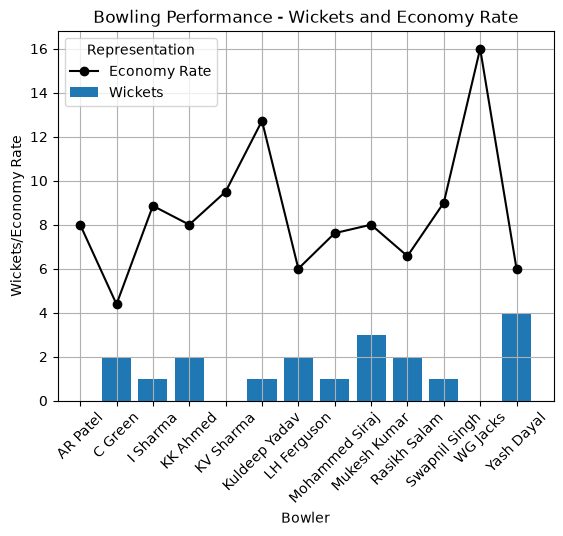

In [13]:
plt.bar(bowling.index,bowling["Wickets"],label="Wickets")
plt.plot(bowling.index,bowling["Economy Rate"],marker='o',color='black',label="Economy Rate")
plt.title("Bowling Performance - Wickets and Economy Rate")
plt.xlabel("Bowler")
plt.ylabel("Wickets/Economy Rate")
plt.xticks(rotation=45)
plt.legend(title="Representation",loc="upper left")
plt.grid(True)
plt.show()




In [14]:
dismissals=df[df["wicket_kind"].notnull()]
dismissal_count=dismissals.groupby('wicket_kind')['player_out'].count()
print(dismissal_count)

wicket_kind
bowled      1
caught     13
lbw         1
run out     4
Name: player_out, dtype: int64


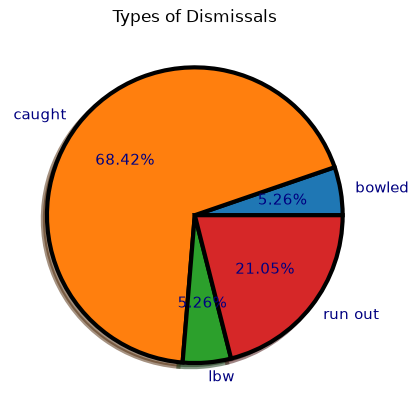

In [15]:
plt.pie(dismissal_count.values,labels=dismissal_count.index,autopct='%1.2f%%',shadow=True,wedgeprops={'edgecolor':'black','linewidth':3},textprops={'color':'navy','fontsize':11})
plt.title("Types of Dismissals")
plt.show()

In [16]:
def get_pair(row):
    players=[row['batter'],row['non_striker']]
    players.sort()
    return players[0]+'&'+players[1]
df["Partnership"]=df.apply(get_pair,axis=1)
print(df[['batter','non_striker','Partnership']].head(10))

         batter   non_striker           Partnership
0       V Kohli  F du Plessis  F du Plessis&V Kohli
1       V Kohli  F du Plessis  F du Plessis&V Kohli
2  F du Plessis       V Kohli  F du Plessis&V Kohli
3       V Kohli  F du Plessis  F du Plessis&V Kohli
4       V Kohli  F du Plessis  F du Plessis&V Kohli
5       V Kohli  F du Plessis  F du Plessis&V Kohli
6  F du Plessis       V Kohli  F du Plessis&V Kohli
7  F du Plessis       V Kohli  F du Plessis&V Kohli
8  F du Plessis       V Kohli  F du Plessis&V Kohli
9       V Kohli  F du Plessis  F du Plessis&V Kohli


In [17]:
partnership_runs=df.groupby("Partnership")["runs_total"].sum()
partnership_runs=partnership_runs.sort_values(ascending=False)
print(partnership_runs.head(10))

Partnership
RM Patidar&WG Jacks              88
AR Patel&SD Hope                 56
AR Patel&Rasikh Salam            37
C Green&MK Lomror                37
F du Plessis&V Kohli             23
Abishek Porel&J Fraser-McGurk    16
C Green&WG Jacks                 13
V Kohli&WG Jacks                 13
C Green&KV Sharma                 9
DA Warner&J Fraser-McGurk         8
Name: runs_total, dtype: int64


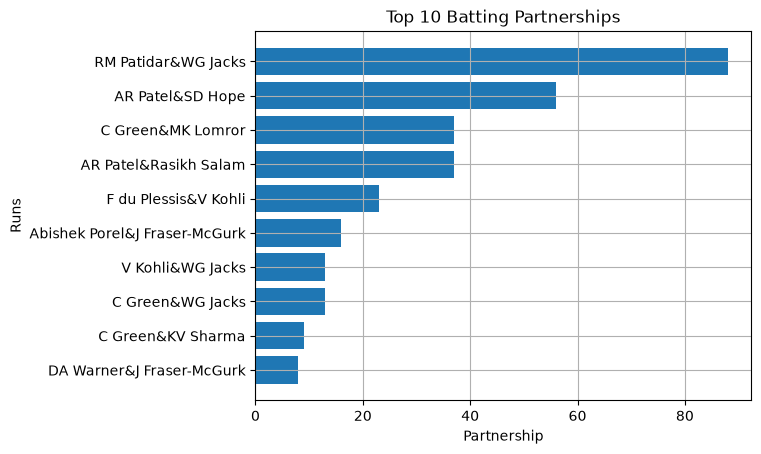

In [20]:
top_partnerships=partnership_runs.head(10)
top_partnerships=top_partnerships.sort_values()
plt.barh(top_partnerships.index,top_partnerships.values)
plt.title("Top 10 Batting Partnerships")
plt.xlabel("Partnership")
plt.ylabel("Runs")
plt.grid(True)
plt.show()

In [24]:
def get_phase(over):
    if over<=5:
        return "Powerplay"
    elif over<=14:
        return "Middle"
    else:
        return "Death"
df["Phase"]=df["over"].apply(get_phase)
print(df[['over','Phase']].head(20))

    over      Phase
0      0  Powerplay
1      0  Powerplay
2      0  Powerplay
3      0  Powerplay
4      0  Powerplay
5      0  Powerplay
6      1  Powerplay
7      1  Powerplay
8      1  Powerplay
9      1  Powerplay
10     1  Powerplay
11     1  Powerplay
12     2  Powerplay
13     2  Powerplay
14     2  Powerplay
15     2  Powerplay
16     2  Powerplay
17     2  Powerplay
18     3  Powerplay
19     3  Powerplay


In [25]:
phase_runs=df.groupby('Phase')['runs_total'].sum()
print(phase_runs)

Phase
Death         62
Middle       150
Powerplay    115
Name: runs_total, dtype: int64


In [26]:
phase_wickets=df[df['player_out'].notnull()].groupby('Phase')['player_out'].count()
print(phase_wickets)

Phase
Death        8
Middle       5
Powerplay    6
Name: player_out, dtype: int64


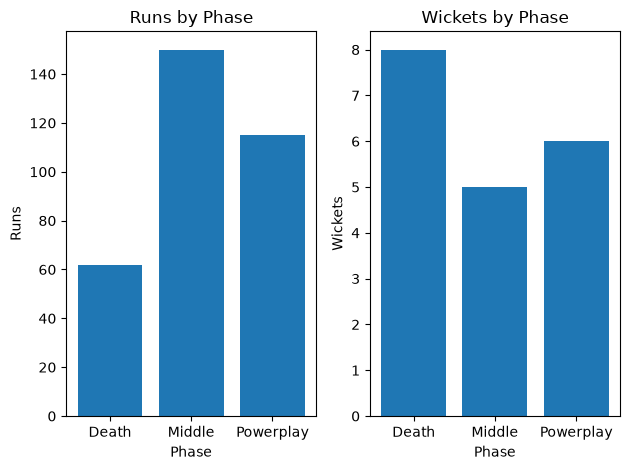

In [27]:
plt.subplot(1,2,1)
plt.bar(phase_runs.index,phase_runs.values)
plt.title("Runs by Phase")
plt.xlabel("Phase")
plt.ylabel("Runs")
plt.subplot(1,2,2)
plt.bar(phase_wickets.index,phase_wickets.values)
plt.title("Wickets by Phase")
plt.xlabel("Phase")
plt.ylabel("Wickets")
plt.tight_layout()
plt.show()

In [28]:
balls_faced=df.groupby('batter')['batter'].count()
strike_rate=(batter_runs/balls_faced)*100
strike_rate=strike_rate.sort_values(ascending=False)
print(strike_rate.head(10))

batter
J Fraser-McGurk    262.500000
V Kohli            192.857143
RM Patidar         152.941176
KV Sharma          150.000000
AR Patel           142.500000
WG Jacks           136.666667
C Green            133.333333
MK Lomror          130.000000
SD Hope            120.833333
F du Plessis        85.714286
dtype: float64


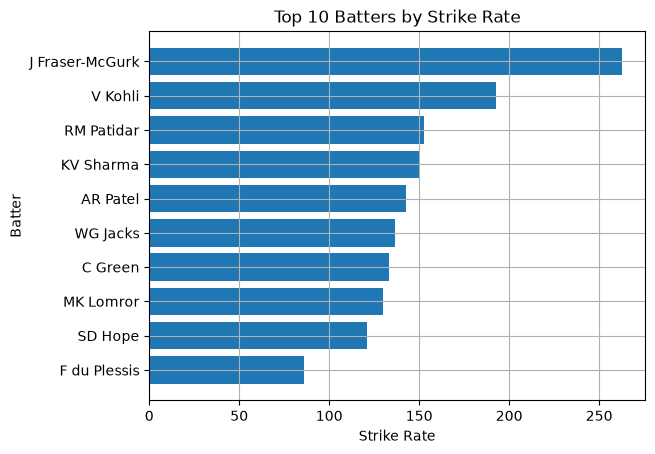

In [29]:
top_10_strike_rate=strike_rate.head(10)
top_10_strike_rate=top_10_strike_rate.sort_values()
plt.barh(top_10_strike_rate.index,top_10_strike_rate.values)
plt.title("Top 10 Batters by Strike Rate")
plt.xlabel("Strike Rate")
plt.ylabel("Batter")
plt.grid(True)
plt.show()

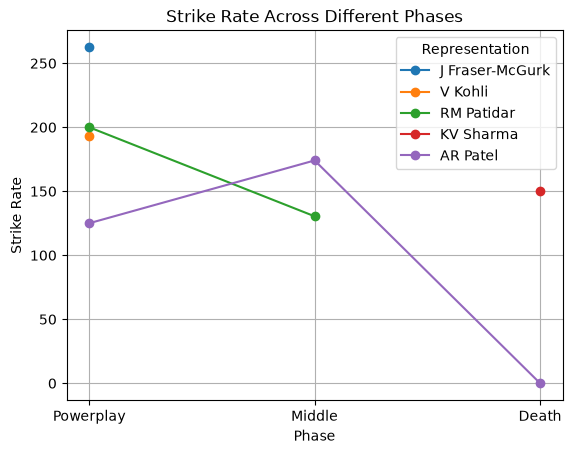

In [34]:
top_performers=strike_rate.head(5).index
for batter in top_performers:
    batter_data=df[df['batter']==batter]
    batter_phase_runs=batter_data.groupby('Phase')['runs_batter'].sum()
    batter_phase_balls=batter_data.groupby('Phase')['batter'].count()
    phase_strike_rate=(batter_phase_runs/batter_phase_balls)*100
    plt.plot(phase_strike_rate.index,phase_strike_rate.values,marker='o',label=batter)
plt.title("Strike Rate Across Different Phases")
plt.xlabel("Phase")
plt.ylabel("Strike Rate")
plt.legend(title="Representation",loc="upper right")
plt.grid(True)
plt.show()

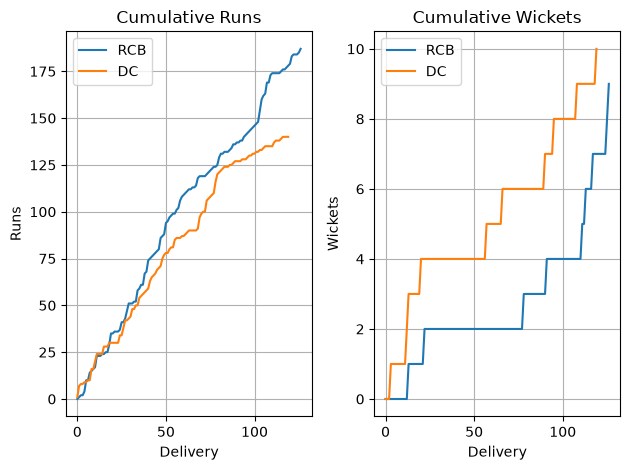

In [40]:
rcb=df[df['team']=="Royal Challengers Bengaluru"]
dc=df[df['team']=="Delhi Capitals"]
rcb_cumulative_runs=[]
total=0
for runs in rcb['runs_total']:
    total=total+runs
    rcb_cumulative_runs.append(total)

dc_cumulative_runs=[]
total=0
for runs in dc['runs_total']:
    total=total+runs
    dc_cumulative_runs.append(total)

rcb_cumulative_wickets=[]
wickets=0
for out in rcb['player_out']:
    if pd.notnull(out):
        wickets=wickets+1
    rcb_cumulative_wickets.append(wickets)

dc_cumulative_wickets=[]
wickets=0
for out in dc['player_out']:
    if pd.notnull(out):
        wickets=wickets+1
    dc_cumulative_wickets.append(wickets)

plt.subplot(1,2,1)
plt.plot(rcb_cumulative_runs,label="RCB")
plt.plot(dc_cumulative_runs,label="DC")
plt.title("Cumulative Runs")
plt.xlabel("Delivery")
plt.ylabel("Runs")
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(rcb_cumulative_wickets,label="RCB")
plt.plot(dc_cumulative_wickets,label="DC")
plt.title("Cumulative Wickets")
plt.xlabel("Delivery")
plt.ylabel("Wickets")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
